# 1주차 · Python과 표 데이터
### 숫자의 뜻을 설명하고, 계산한 결과를 확인하기

화분 여섯 개를 관찰한 작은 표로 시작합니다. 한 줄이 무엇을 뜻하는지 읽고, 평균과 분산을 손으로 구한 뒤 Python으로 같은 계산을 확인합니다. 마지막에는 그래프의 점 하나를 원래 표에서 찾아 설명합니다.

대상은 변수·조건문·반복문·함수·리스트를 써 본 중학생입니다. AI를 미리 공부할 필요는 없습니다. 예제의 화분과 수치는 수업용으로 만든 합성 자료이며 실제 실험 결과가 아닙니다.

이 노트북의 설명과 실행 예제는 수업 자료입니다. 빈 답안 칸은 학생이 직접 채웁니다. 예제 코드가 실행됐다는 사실만으로 학생의 이해나 수업 완료를 판정하지 않습니다.


## 목표 · 오늘 직접 설명할 것

수업을 마치면 다음을 자신의 말과 계산으로 설명해 봅니다.

- 표의 행·열, 특성·정답을 구분하고 측정 단위를 말합니다.
- 평균과 분산의 계산 순서를 쓰고, 분산에서 제곱과 나눗셈이 필요한 이유를 설명합니다.
- 2차원 배열의 shape와 axis별 평균의 값·결과 모양을 실행 전에 예상합니다.
- CSV에서 필요한 행·열을 고르고, 결측값과 실제 0을 구분합니다.
- 축과 단위를 갖춘 그래프를 만들고, 그래프에서 말할 수 있는 범위를 설명합니다.

| 수업 시각 | 할 일 | 분류 |
|---|---|---|
| 0~5분 | 한 행의 뜻, 특성과 정답 | 이론 5분 |
| 5~12분 | 평균·분산의 식과 단위 | 이론 7분 |
| 12~20분 | 배열의 모양, 축을 줄이는 계산 | 이론 8분 |
| 20~30분 | axis별 평균을 종이에 계산 | 손풀이 10분 |
| 30~40분 | 필기 네 문항과 해설 | 필기 10분 |
| 40~60분 | Python 다섯 문항 진단과 보충 | 코딩 20분 |
| 60~100분 | CSV 읽기·선택·결측 탐지·새 열 이름 | 코딩 40분 |
| 100~120분 | NumPy 확인, 그래프 작성·해석 | 코딩 20분 |

합계는 120분입니다. 시간은 편성 추정치이며 학생이 실제로 수행한 시간은 아직 측정하지 않았습니다. 뒤의 **다음 학습 · 수업 밖 과제**는 이 120분에 포함하지 않습니다.


## 준비 · 수업 전에 한 번만 확인하기

Python 3 커널과 NumPy, pandas, Matplotlib을 사용합니다. Seaborn은 수업 밖 시각화 과제에서 사용합니다. 설치와 첫 접속은 수업 전에 마칩니다.

JupyterLab에서는 셀을 선택하고 **Shift+Enter**를 누르면 실행됩니다. Markdown 셀을 두 번 누르면 글을 고칠 수 있습니다. 코드 셀의 대괄호에 별표가 보이면 실행 중입니다. 저장은 **Ctrl+S**입니다. 처음부터 다시 확인하려면 **Kernel → Restart Kernel and Run All Cells**를 선택합니다.

다음 셀은 자료 읽기와 그림 표시에 필요한 준비 코드입니다. 반복해서 실행해도 표의 값은 바뀌지 않습니다.


In [1]:
from pathlib import Path
from io import StringIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

%matplotlib inline
available_fonts = {item.name for item in font_manager.fontManager.ttflist}
for font_name in ["Malgun Gothic", "AppleGothic", "NanumGothic",
                  "Noto Sans CJK KR", "Noto Sans CJK JP"]:
    if font_name in available_fonts:
        plt.rcParams["font.family"] = font_name
        break
plt.rcParams.update({"figure.figsize": (8, 4.6), "font.size": 12,
                     "axes.unicode_minus": False, "axes.spines.top": False,
                     "axes.spines.right": False})
print("준비 완료. 이후 셀은 위에서 아래 순서로 실행합니다.")


준비 완료. 이후 셀은 위에서 아래 순서로 실행합니다.


## 수업 · 개념부터 읽기

### 1. 한 행은 화분 하나의 기록입니다 · 0~5분

같은 종류의 어린 식물을 서로 다른 화분에 심었다고 가정합니다. 빛을 받은 시간과 준 물의 양을 기록하고, 일주일 뒤 높이를 잽니다. 여기서는 기록 방법을 배우기 위해 만든 숫자를 사용합니다.

| 화분 번호 | 장소 | 하루 빛을 받은 시간(h) | 하루 준 물(ml) | 일주일 뒤 높이(cm) |
|---|---|---:|---:|---:|
| P01 | 실내 | 2 | 0 | 8 |
| P02 | 실내 | 3 | 20 | 10 |
| P03 | 창가 | 5 | 기록 없음 | 12 |
| P04 | 창가 | 6 | 40 | 14 |
| P05 | 실내 | 4 | 20 | 10 |
| P06 | 창가 | 7 | 60 | 18 |

한 **행**은 화분 하나의 관찰 기록이고, 한 **열**은 같은 종류의 정보입니다. 주어진 정보로 높이를 예측하는 문제라면 빛의 시간과 물의 양을 **특성(feature)**, 알아맞힐 높이를 정답(target)이라고 부릅니다. 정답이라는 말은 이 표에 기록한 비교 대상이라는 뜻입니다. 측정이 완벽하다는 뜻까지 담고 있지는 않습니다.

P01의 물 0ml는 물을 주지 않았다고 기록한 값입니다. P03의 빈칸은 물의 양을 모른다는 뜻입니다. 빈칸을 0으로 바꾸면 서로 다른 상황을 같은 값으로 만들게 됩니다. 화분 번호는 기록을 찾는 식별자입니다.

이 표로는 모델을 학습하지 않습니다. 높이가 큰 화분에서 빛의 시간이 길게 나타나더라도, 이 예제만으로 빛이 높이의 차이를 만들었다고 판단할 수는 없습니다.


### 2. 평균은 합계를 같은 몫으로 나눈 값입니다 · 5~12분

길이가 2cm, 4cm, 6cm인 세 막대를 생각해 봅니다. 길이의 합은 12cm이고 막대는 세 개이므로, 똑같이 나눈 길이는 4cm입니다.

$$
\bar{x}=\frac{x_1+x_2+\cdots+x_n}{n}
       =\frac{1}{n}\sum_{i=1}^{n}x_i.
$$

| 기호 | 이 수업에서의 뜻 |
|---|---|
| $n$ | 값의 개수. 1 이상의 정수 |
| $i$ | 몇 번째 값인지 나타내는 번호. 1부터 $n$까지 |
| $x_i$ | $i$번째 값. 여기서는 cm로 잰 길이 |
| $\sum_{i=1}^{n}x_i$ | 첫 값부터 마지막 값까지 더한다는 표기 |
| $\bar{x}$ | 평균. 읽을 때는 ‘엑스 바’라고 부르며 단위는 cm |

이 식은 유한한 숫자가 하나 이상 있고 모두 같은 종류·단위의 양일 때 사용합니다. 빈칸이 있는 표는 어떤 값을 계산에 포함했는지 먼저 정해야 합니다. 물의 양(ml)과 길이(cm)를 더한 평균은 여기서 해석하지 않습니다.

계산을 식으로 따라가면 $\bar{x}=(2+4+6)/3=12/3=4\text{ cm}$입니다. 평균은 실제 관측값 중 하나일 필요가 없습니다. 예를 들어 2와 3의 평균 2.5는 두 관측값 사이에 있습니다.


### 같은 평균이어도 퍼진 정도는 다릅니다

길이가 [2, 4, 6]인 묶음과 [4, 4, 4]인 묶음의 평균은 모두 4cm입니다. 평균 하나로는 두 묶음을 구별하기 어렵습니다.

각 값에서 평균을 빼면 **편차**입니다. 첫 묶음의 편차는 $[-2,0,2]$cm입니다. 그대로 더하면 $-2+0+2=0$이 되어 퍼진 정도가 사라집니다. 여기서는 편차를 제곱해 음수와 양수가 서로 지워지지 않게 합니다. 값의 개수가 다른 묶음도 비교할 수 있도록 제곱합을 개수로 나눕니다.

$$
v=\frac{1}{n}\sum_{i=1}^{n}(x_i-\bar{x})^2.
$$

$v$는 **분산**이며, 나머지 기호는 바로 위 평균 식과 같습니다. 이 수업에서는 지금 가진 값 전체의 퍼짐을 기술하므로 분모를 $n$으로 정합니다. 표본으로 더 큰 집단의 분산을 추정할 때 쓰는 $n-1$ 공식은 이번 계산에 쓰지 않습니다.

| 단계 | 2cm | 4cm | 6cm |
|---|---:|---:|---:|
| 평균 4cm를 빼기 | -2cm | 0cm | 2cm |
| 편차를 제곱하기 | 4cm² | 0cm² | 4cm² |

제곱합은 $4+0+4=8\text{ cm}^2$, 분산은 $8/3\approx2.67\text{ cm}^2$입니다. [4, 4, 4]에서는 편차가 모두 0이므로 분산도 0입니다. 제곱했기 때문에 분산의 단위는 원래 단위의 제곱입니다.


### 평균 계산을 순서로 적으면 알고리즘이 됩니다

**알고리즘**은 입력을 받아 결과를 만드는 절차입니다. 다음 표기는 Python 문법에 매이지 않고 계산 순서를 적은 **의사코드**입니다. 입력은 빈칸이 없는, 같은 단위의 숫자 목록입니다. 빈 목록의 평균은 정하지 않고 오류로 알립니다.

~~~text
평균_구하기(숫자_목록):
    개수 ← 목록에 든 값의 수
    개수가 0이면 오류를 알리고 끝낸다
    합계 ← 0
    목록의 각 값을 하나씩 읽는다:
        합계 ← 지금 합계 + 읽은 값
    합계 / 개수를 결과로 돌려준다
~~~

화살표 $\leftarrow$는 오른쪽 값을 왼쪽 이름에 저장한다는 뜻입니다. 수학의 등호처럼 두 값이 항상 같다고 선언하는 표기와 구분합니다. Python의 대입에는 <code>=</code>를 쓰고, 계산한 결과를 호출한 곳에 돌려줄 때는 <code>return</code>을 씁니다.

| [2, 4, 6]에서의 시점 | 읽은 값 | 누적 합계 |
|---|---:|---:|
| 시작 | 아직 없음 | 0 |
| 한 번 읽음 | 2 | 2 |
| 두 번 읽음 | 4 | 6 |
| 세 번 읽음 | 6 | 12 |
| 결과 반환 | 개수 3으로 나눔 | 4 |

분산은 평균을 먼저 구한 다음, 각 편차의 제곱을 같은 방법으로 누적해 개수로 나눕니다. 코드를 실행하기 전에 이 순서를 손으로 따라갈 수 있으면, 잘못된 결과가 나왔을 때 어느 단계부터 살필지도 정할 수 있습니다.


### 3. shape는 값이 놓인 자리의 수입니다 · 12~20분

같은 단위(cm)로 잰 길이 여섯 개를 3행 2열로 놓겠습니다.

$$
A=
\begin{bmatrix}
2&4\\
6&8\\
10&12
\end{bmatrix},
\qquad \mathrm{shape}(A)=(3,2).
$$

**shape**는 차례대로 각 축의 길이를 적은 것입니다. 이 2차원 배열의 첫 축 **axis=0** 길이는 행 수 3, 둘째 축 **axis=1** 길이는 열 수 2입니다. 수학에서는 $a_{ij}$로 $i$행 $j$열 값을 나타내며 여기서 $i=1,2,3$, $j=1,2$입니다. Python은 0부터 세므로 수학의 $a_{12}=4$는 코드의 <code>A[0, 1]</code>에 대응합니다.

평균을 구할 때 <code>axis</code>는 **어느 축을 줄일지** 지정합니다. 이 수업의 배열은 직사각형이며, 모든 값은 유한한 숫자입니다. <code>keepdims=False</code>로 줄인 축은 결과에서 사라집니다.

- <code>axis=0</code>: 행 축의 세 값을 모아 평균을 냅니다. 열마다 하나씩 남으므로 결과는 [6, 8], shape는 <code>(2,)</code>입니다.
- <code>axis=1</code>: 열 축의 두 값을 모아 평균을 냅니다. 행마다 하나씩 남으므로 결과는 [3, 7, 11], shape는 <code>(3,)</code>입니다.

<code>(2,)</code>의 쉼표는 한 축만 있는 shape 표기입니다. 2행 1열인 <code>(2, 1)</code>과는 모양이 다릅니다.


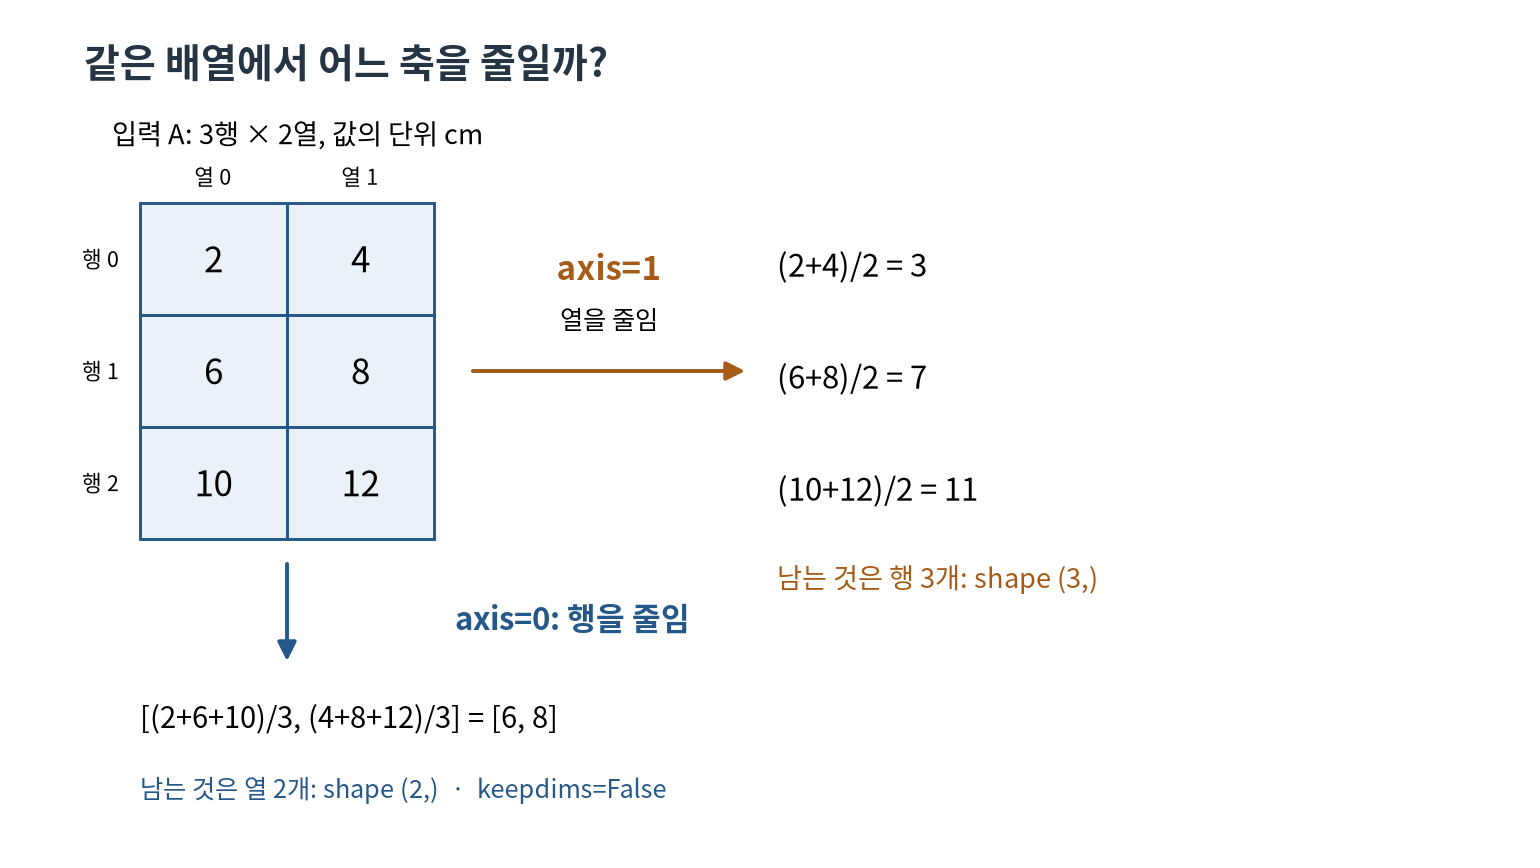

그림의 화살표 방향만 외우지 말고, 평균 하나를 만들 때 어떤 값을 묶었는지 확인합니다.


일반적인 $m$행 $p$열 배열에서도 같은 순서로 계산합니다. $m,p$는 모두 1 이상의 정수이고, 모든 원소의 단위는 같습니다.

$$
c_j=\frac{1}{m}\sum_{i=1}^{m}a_{ij}\quad(j=1,\ldots,p),
\qquad
r_i=\frac{1}{p}\sum_{j=1}^{p}a_{ij}\quad(i=1,\ldots,m).
$$

$c_j$는 $j$번째 열의 평균, $r_i$는 $i$번째 행의 평균입니다. 첫 식은 행 번호 $i$를 움직이므로 행 축을 줄입니다. 둘째 식은 열 번호 $j$를 움직이므로 열 축을 줄입니다. 결과로 남은 번호가 각각 $j$, $i$라는 점을 코드의 결과 길이와 연결해 봅니다.


### 4. 종이에 먼저 계산하기 · 20~30분

위 배열 $A$를 보고 계산합니다. NumPy 셀은 아직 실행하지 않습니다.

1. <code>A[1, 0]</code>은 얼마인가요? 수학의 $a_{ij}$로도 적으세요.
2. 첫 열과 둘째 열을 각각 더하고 개수로 나누세요. <code>mean(axis=0)</code>의 값과 shape를 적으세요.
3. 세 행의 평균을 구하세요. <code>mean(axis=1)</code>의 값과 shape를 적으세요.
4. <code>axis</code>를 쓰지 않고 여섯 값을 모두 평균 내면 얼마인가요?

답을 구한 뒤 한 평균을 골라 분자에 포함한 값과 분모의 뜻을 친구에게 설명합니다. 마지막 2분에 서로 계산을 대조합니다.


**손풀이에 내 말로 답하기**

예상한 값 또는 설명:  

계산하거나 판단한 이유:  

실행 뒤 달라진 생각:  

받은 도움: 없음 / 힌트 / 예시 / 직접 설명 중 적기.


### 5. 필기로 설명 확인하기 · 30~40분

먼저 6분 동안 네 문항에 답합니다. 남은 4분은 설명을 비교하고 잘못 생각한 부분을 고칩니다.

- **가.** shape가 <code>(4, 3)</code>인 2차원 배열을 <code>mean(axis=0, keepdims=False)</code>로 줄였습니다. 결과의 shape와 평균 하나에 들어간 값의 개수를 쓰세요.
- **나.** 같은 배열을 <code>mean(axis=1, keepdims=False)</code>로 줄였습니다. 결과의 shape와 분모를 쓰세요.
- **다.** [2, 4, 6]의 모든 값에 10cm를 더했습니다. 평균과 분산은 각각 어떻게 바뀌나요? 편차를 써서 설명하세요.
- **라.** 화분의 물 기록이 [0, 기록 없음, 20]ml입니다. 빈칸을 0으로 바꾼 평균과, 기록된 두 값의 평균은 왜 뜻이 다른가요?

단위 없는 숫자만 쓰지 말고, 무엇을 평균 냈는지도 적습니다.


**필기 네 문항에 내 말로 답하기**

예상한 값 또는 설명:  

계산하거나 판단한 이유:  

실행 뒤 달라진 생각:  

받은 도움: 없음 / 힌트 / 예시 / 직접 설명 중 적기.


### 6. Python에서 막히는 지점 찾기 · 40~60분

12분 동안 다섯 문항을 읽고 실행 전 결과를 적습니다. 뒤의 코드 셀로 확인한 다음 남은 8분 동안 틀린 문항의 첫 번째 원인을 찾습니다. 함수나 반복문이 낯설면 다음 주 전에 보충 시간을 따로 기록합니다.

**진단 1 · 저장된 값과 조건문**

~~~python
water = 10
water = water + 5
if water >= 15:
    label = "충분"
else:
    label = "부족"
~~~

마지막 <code>water</code>와 <code>label</code>은 무엇인가요?

**진단 2 · 반복문**

~~~python
total = 0
for value in [2, 4, 6]:
    total = total + value
~~~

반복 횟수와 매번의 <code>total</code>을 쓰세요.

**진단 3 · 반환과 화면 출력**

~~~python
def twice(value):
    return value * 2

def show_twice(value):
    print(value * 2)
~~~

<code>twice(3)</code>과 <code>show_twice(3)</code>을 변수에 저장하면 각 변수에 무엇이 들어가나요? 화면에 무엇이 보이는지도 따로 적으세요.

**진단 4 · 인덱스와 슬라이스**

~~~python
values = [8, 10, 12, 14]
chosen = values[1:3]
~~~

<code>values[0]</code>과 <code>chosen</code>은 무엇인가요? <code>values</code> 자체도 줄어들까요?

**진단 5 · 파일과 오류**

<code>pd.read_csv("data/week1_plants.csv")</code>에서 <code>FileNotFoundError</code>가 나면 무엇을 먼저 확인해야 하나요? 파일을 읽은 뒤 <code>table["height"]</code>에서 <code>KeyError: 'height'</code>가 나면 같은 방법으로 해결할 수 있을까요?


**Python 진단에 내 말로 답하기**

예상한 값 또는 설명:  

계산하거나 판단한 이유:  

실행 뒤 달라진 생각:  

받은 도움: 없음 / 힌트 / 예시 / 직접 설명 중 적기.


#### 예측을 적은 뒤 확인하기

화면 출력과 반환값을 서로 다른 줄에서 확인합니다. 오류 이름은 뒤의 CSV 활동에서 실제로 다시 다룹니다.


In [2]:
water = 10
water = water + 5
label = "충분" if water >= 15 else "부족"
print("진단 1:", water, label)

total = 0
for value in [2, 4, 6]:
    total = total + value
    print("읽은 값과 누적 합계:", value, total)


진단 1: 15 충분
읽은 값과 누적 합계: 2 2
읽은 값과 누적 합계: 4 6
읽은 값과 누적 합계: 6 12


In [3]:
def twice(value):
    return value * 2

def show_twice(value):
    print(value * 2)

returned = twice(3)
shown = show_twice(3)
print("return으로 받은 값:", returned)
print("print만 한 함수에서 받은 값:", shown)
values = [8, 10, 12, 14]
print("첫 값:", values[0], "/ 선택:", values[1:3], "/ 원본:", values)


6
return으로 받은 값: 6
print만 한 함수에서 받은 값: None
첫 값: 8 / 선택: [10, 12] / 원본: [8, 10, 12, 14]


화면에 6이 보였어도 <code>show_twice</code>는 계산값을 돌려주지 않았습니다. 명시한 <code>return</code>이 없는 함수의 반환값은 <code>None</code>입니다. 뒤 계산에 쓸 값은 함수에서 돌려받아야 합니다.

평균 알고리즘을 다음처럼 Python으로 옮깁니다. <code>len</code>은 개수를 구하고, <code>raise</code>는 정한 오류를 알립니다. 이 함수의 입력은 빈칸이 없는 유한한 숫자 목록으로 한정합니다. 이론의 $n$, 합계, 나눗셈이 각각 어느 줄에 있는지 짚어 보세요.


In [4]:
def mean_of_numbers(numbers):
    count = len(numbers)
    if count == 0:
        raise ValueError("평균을 구할 값이 하나 이상 필요합니다.")
    total = 0
    for value in numbers:
        total = total + value
    return total / count

print("[2, 4, 6]의 평균:", mean_of_numbers([2, 4, 6]))
try:
    mean_of_numbers([])
except ValueError as error:
    print("빈 목록을 넣었을 때:", error)


[2, 4, 6]의 평균: 4.0
빈 목록을 넣었을 때: 평균을 구할 값이 하나 이상 필요합니다.


#### 새 입력에 적용하기

완성한 예제를 가리고 [1, 3, 8]에서 반복할 때마다 합계가 어떻게 바뀌는지 적으세요. 평균 함수의 입력이 []일 때 0을 돌려주지 않는 이유도 설명하세요. 도움을 받았다면 답안 칸에 표시합니다.


**함수 새 입력에 내 말로 답하기**

예상한 값 또는 설명:  

계산하거나 판단한 이유:  

실행 뒤 달라진 생각:  

받은 도움: 없음 / 힌트 / 예시 / 직접 설명 중 적기.


### 7. CSV를 표로 읽기 · 60~70분

CSV는 한 줄에 기록 하나를 쓰고, 쉼표로 열을 구분한 텍스트 파일입니다. 첫 줄에는 열 이름을 둡니다. 이 수업의 파일은 <code>data/week1_plants.csv</code>입니다. 함께 받은 폴더를 그대로 열면 이 파일을 읽습니다. 노트북 하나만 옮긴 경우에는 아래에 포함된 같은 CSV 문자열을 읽습니다.

자료사전은 열의 뜻과 단위, 빈칸의 의미를 정리한 표입니다.

| 열 이름 | 뜻 | 단위·종류 | 이 수업의 역할 |
|---|---|---|---|
| pot_id | 화분 식별 번호 | 문자열 | 기록 찾기 |
| place | 관찰 장소 | 실내 또는 창가 | 범주 비교 |
| sunlight_hours | 하루 빛을 받은 시간 | h, 수치 | 예측에 쓸 특성 |
| water_ml | 하루 준 물 | ml, 수치, 1개 누락 | 예측에 쓸 특성 |
| height_cm | 일주일 뒤 높이 | cm, 수치 | 예측할 정답 |

<code>pd.read_csv</code>는 CSV를 pandas의 표인 <code>DataFrame</code>으로 읽습니다. 빈 물 기록은 <code>NaN</code>으로 표시됩니다. <code>NaN</code>은 결측을 나타내는 표식이며 실제 물의 양을 뜻하는 숫자가 아닙니다.


In [5]:
csv_text = 'pot_id,place,sunlight_hours,water_ml,height_cm\nP01,실내,2,0,8\nP02,실내,3,20,10\nP03,창가,5,,12\nP04,창가,6,40,14\nP05,실내,4,20,10\nP06,창가,7,60,18\n'
csv_path = Path("data/week1_plants.csv")
if csv_path.is_file():
    plants = pd.read_csv(csv_path)
    print("읽은 자료:", csv_path)
else:
    plants = pd.read_csv(StringIO(csv_text))
    print("읽은 자료: 노트북에 포함된 동일한 CSV")
display(plants)


읽은 자료: data/week1_plants.csv


,pot_id,place,sunlight_hours,water_ml,height_cm
0,P01,실내,2,0.0,8
1,P02,실내,3,20.0,10
2,P03,창가,5,NaN,12
3,P04,창가,6,40.0,14
4,P05,실내,4,20.0,10
5,P06,창가,7,60.0,18


표가 열렸다면 먼저 <code>shape</code>, <code>columns</code>, <code>dtypes</code>를 봅니다. <code>dtypes</code>는 각 열의 저장 자료형입니다. 수치 열을 문자열로 읽었다면, 문자나 단위가 섞였는지 원자료부터 확인합니다. 결측 때문에 정수처럼 보이는 값이 소수 자료형으로 읽히는 일도 있습니다. 자료형의 정확한 표시 이름은 pandas 버전에 따라 조금 달라질 수 있습니다.


In [6]:
print("행 수와 열 수:", plants.shape)
print("열 이름:", list(plants.columns))
display(plants.dtypes.rename("저장 자료형").to_frame())


행 수와 열 수: (6, 5)
열 이름: ['pot_id', 'place', 'sunlight_hours', 'water_ml', 'height_cm']


,저장 자료형
pot_id,str
place,str
sunlight_hours,int64
water_ml,float64
height_cm,int64


### 8. 행과 열을 따로 고르기 · 70~80분

<code>plants[["sunlight_hours", "water_ml"]]</code>는 두 열을 고릅니다. 대괄호 안의 열 이름 목록이 새 표의 열 순서도 정합니다.

<code>plants["sunlight_hours"] >= 5</code>는 각 행에 대해 조건이 맞는지 <code>True</code> 또는 <code>False</code>로 답합니다. <code>.loc[행 조건, 열 목록]</code>에 넣으면 그 조건을 만족한 행과 지정한 열을 함께 고릅니다.

먼저 빛이 5h 이상인 화분 번호와 예상 행 수를 종이에 적으세요. 그다음 아래 셀을 실행합니다.


In [7]:
feature_columns = ["sunlight_hours", "water_ml"]
features = plants[feature_columns]
target = plants["height_cm"]
print("특성 표 shape:", features.shape)
print("정답 열 shape:", target.shape)

enough_light = plants["sunlight_hours"] >= 5
display(plants.loc[enough_light, ["pot_id", "sunlight_hours", "height_cm"]])


특성 표 shape: (6, 2)
정답 열 shape: (6,)


,pot_id,sunlight_hours,height_cm
2,P03,5,12
3,P04,6,14
5,P06,7,18


특성 두 개는 여섯 화분마다 하나씩 있으므로 <code>features.shape</code>는 (6, 2)입니다. 정답은 화분마다 높이 하나여서 <code>target.shape</code>는 (6,)입니다. 열을 고를 때도 높이 열을 특성에 넣지 않았는지 확인합니다.

직접 고쳐 볼 때는 원본 <code>plants</code>를 덮어쓰지 말고 새 이름에 결과를 저장합니다. 조건을 6h 이상으로 바꿔 선택되는 화분과 개수를 설명하세요.


**행·열 선택에 내 말로 답하기**

예상한 값 또는 설명:  

계산하거나 판단한 이유:  

실행 뒤 달라진 생각:  

받은 도움: 없음 / 힌트 / 예시 / 직접 설명 중 적기.


### 9. 모르는 값과 0을 구분하기 · 80~90분

<code>isna()</code>는 결측인 자리를 <code>True</code>로 표시합니다. 그 결과를 <code>sum()</code>으로 더하면 <code>True</code>를 1로 세어 열별 결측 개수를 구합니다. 원래 관측값의 합을 구하는 것이 아니라, 결측 여부를 센다는 점에 주의합니다.


In [8]:
missing_counts = plants.isna().sum()
display(missing_counts.rename("결측 개수").to_frame())
display(plants.loc[plants["water_ml"].isna(), ["pot_id", "water_ml"]])
display(plants.loc[plants["water_ml"] == 0, ["pot_id", "water_ml"]])


,결측 개수
pot_id,0
place,0
sunlight_hours,0
water_ml,1
height_cm,0


,pot_id,water_ml
2,P03,NaN


,pot_id,water_ml
0,P01,0.0


물 기록은 0, 20, 결측, 40, 20, 60ml입니다. **기록된 다섯 값의 평균**은 $(0+20+40+20+60)/5=28$ml입니다. 여섯 화분 전체의 실제 평균은 빈칸의 값을 알기 전에는 구할 수 없습니다.

pandas의 <code>mean()</code>은 기본적으로 결측을 제외합니다. 분모를 숨기지 않도록 개수도 함께 출력합니다. 이번 주에는 결측을 탐지하고 계산에 포함한 범위를 밝힙니다. 빈칸을 채우는 전처리와 그 값을 정할 데이터 분할은 2주차에 다룹니다.


In [9]:
recorded_water = plants["water_ml"].dropna()
print("기록된 물 값의 개수:", len(recorded_water))
print("기록된 물 값의 합(ml):", recorded_water.sum())
print("기록된 값의 평균(ml):", recorded_water.mean())
print("원래 표의 결측 개수:", plants["water_ml"].isna().sum())


기록된 물 값의 개수: 5
기록된 물 값의 합(ml): 140.0
기록된 값의 평균(ml): 28.0
원래 표의 결측 개수: 1


### 10. 열 이름이 바뀌었을 때 · 90~100분

<code>FileNotFoundError</code>는 파일 위치부터 살핍니다. <code>KeyError</code>는 읽은 표에 요청한 열이 있는지 확인합니다. 두 오류는 실패한 단계가 다릅니다.

아래 함수는 필요한 열이 빠졌으면 어떤 열이 없는지 알립니다. <code>column not in table.columns</code>는 그 열 이름이 표에 없는지 검사합니다. 모르는 열을 조용히 빈 값으로 만들어 계속하지 않습니다.


In [10]:
def require_columns(table, required_columns):
    missing_columns = []
    for column in required_columns:
        if column not in table.columns:
            missing_columns.append(column)
    if missing_columns:
        raise KeyError(f"없는 열: {missing_columns}")
    return table[required_columns]

print("현재 높이 열:", require_columns(plants, ["height_cm"]).shape)
try:
    require_columns(plants, ["height"])
except KeyError as error:
    print("예상한 오류를 확인했습니다:", error)


현재 높이 열: (6, 1)
예상한 오류를 확인했습니다: "없는 열: ['height']"


새 파일에서는 이름이 <code>height_cm</code>에서 <code>final_height_cm</code>로 바뀌었습니다. 아래는 코드가 찾을 열 이름만 바로잡는 예입니다. 열의 의미나 단위까지 같은지 확인한 뒤 적용합니다.


In [11]:
renamed = plants.rename(columns={"height_cm": "final_height_cm"})
new_target_column = "final_height_cm"
display(require_columns(renamed, ["pot_id", new_target_column]).head(3))


,pot_id,final_height_cm
0,P01,8
1,P02,10
2,P03,12


#### 도움 없이 해 볼 작은 변경

높이 열 이름을 <code>growth_cm</code>로 바꾼 새 표에서 빛 4h 이하인 화분 번호와 높이를 골라 보세요. 실행 전에 결과의 행 수와 열 수를 적습니다. 이어 물 열에 <code>"20ml"</code> 같은 문자가 들어 있다면 자료형과 평균 계산에서 무엇을 먼저 확인할지 적습니다. 해결 과정을 설명한 뒤 필요하면 힌트를 요청합니다.


In [12]:
# 이 표를 입력으로 사용합니다. 아래에 선택 코드를 직접 덧붙이세요.
changed_plants = plants.rename(columns={"height_cm": "growth_cm"})


**열 이름이 바뀐 표에 내 말로 답하기**

예상한 값 또는 설명:  

계산하거나 판단한 이유:  

실행 뒤 달라진 생각:  

받은 도움: 없음 / 힌트 / 예시 / 직접 설명 중 적기.


### 11. 손계산을 NumPy와 대조하기 · 100~108분

위에서 계산한 배열을 그대로 만듭니다. <code>mean(axis=...)</code>의 결과는 두 벡터이고, <code>mean()</code>의 결과는 전체 여섯 값의 평균인 숫자 하나입니다. 출력 길이가 예상과 다르면 먼저 줄일 축을 다시 확인합니다.


In [13]:
A = np.array([[2, 4], [6, 8], [10, 12]], dtype=float)
column_means = A.mean(axis=0, keepdims=False)
row_means = A.mean(axis=1, keepdims=False)
print("입력 shape:", A.shape)
print("열별 평균(cm):", column_means, "/ shape:", column_means.shape)
print("행별 평균(cm):", row_means, "/ shape:", row_means.shape)
print("전체 평균(cm):", A.mean())


입력 shape: (3, 2)
열별 평균(cm): [6. 8.] / shape: (2,)
행별 평균(cm): [ 3.  7. 11.] / shape: (3,)
전체 평균(cm): 7.0


분산은 NumPy와 pandas 모두 분모를 $n$으로 맞추어 비교합니다. NumPy <code>var</code>의 기본 <code>ddof</code>는 0이고 pandas <code>var</code>의 기본은 1입니다. 여기서는 두 쪽 모두 <code>ddof=0</code>을 명시합니다. 분모는 <code>n - ddof</code>입니다.

표의 물 열에는 결측이 있으므로 방금 만든 결측 없는 배열과 섞어 계산하지 않습니다.


In [14]:
lengths = np.array([2, 4, 6], dtype=float)
mean_length = lengths.mean()
squared_deviations = (lengths - mean_length) ** 2
print("평균(cm):", mean_length)
print("편차의 제곱(cm²):", squared_deviations)
print("손계산 순서의 분산(cm²):", squared_deviations.sum() / len(lengths))
print("NumPy 분산(ddof=0):", lengths.var(ddof=0))
print("pandas 분산(ddof=0):", pd.Series(lengths).var(ddof=0))


평균(cm): 4.0
편차의 제곱(cm²): [4. 0. 4.]
손계산 순서의 분산(cm²): 2.6666666666666665
NumPy 분산(ddof=0): 2.6666666666666665
pandas 분산(ddof=0): 2.6666666666666665


### 12. 그래프의 점을 표의 행과 연결하기 · 108~120분

아래 **산점도**의 점 하나는 화분 하나입니다. 가로 위치는 하루 빛을 받은 시간(h), 세로 위치는 일주일 뒤 높이(cm)입니다. 선으로 점을 잇지 않으며, 화분 번호로 원래 행을 찾을 수 있게 합니다.

먼저 P03이 놓일 좌표를 (가로, 세로) 순서로 적습니다. 그다음 그림을 실행하고 $(5,12)$인지 확인합니다. 두 축은 서로 다른 단위를 가져도 됩니다. 각 축이 무엇인지 따로 정하기 때문입니다.


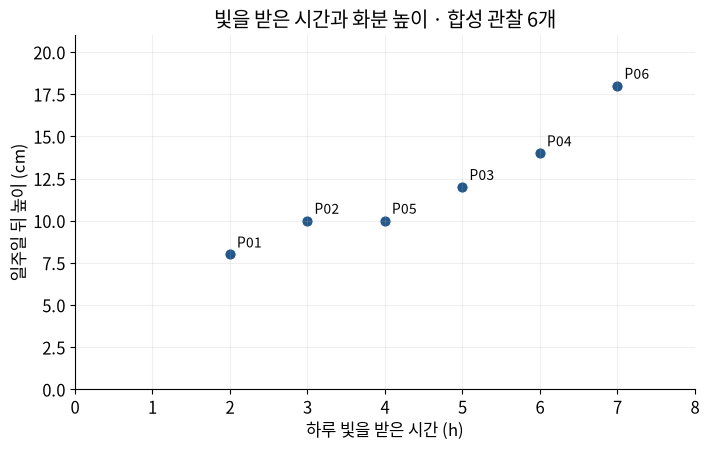

In [15]:
fig, ax = plt.subplots()
ax.scatter(plants["sunlight_hours"], plants["height_cm"],
           s=65, color="#24578A", edgecolor="white", linewidth=0.7)
for row in plants.itertuples():
    ax.annotate(row.pot_id, (row.sunlight_hours, row.height_cm),
                xytext=(5, 5), textcoords="offset points", fontsize=10)
ax.set(title="빛을 받은 시간과 화분 높이 · 합성 관찰 6개",
       xlabel="하루 빛을 받은 시간 (h)", ylabel="일주일 뒤 높이 (cm)",
       xlim=(0, 8), ylim=(0, 21))
ax.grid(alpha=0.2)
plt.show()


이 예제에서는 빛이 2h인 P01 높이는 8cm, 7h인 P06 높이는 18cm입니다. 점의 위치는 표와 일치해야 합니다. 여섯 개의 합성 관찰을 그린 그림이므로, 실제 식물 전체에 대한 법칙이나 원인 관계를 결론 내리지 않습니다.

남은 시간에는 아래 두 가지를 합니다.

1. 가로축의 빛 시간을 모두 1h씩 늘린 **복사본**을 만들면 그림이 어떻게 이동할지 예측하고 다시 그립니다. 원본 표는 보존합니다.
2. 그림만 본 친구에게 점 하나의 뜻, 축의 단위, 그림으로 확인하지 못한 사실 한 가지를 설명합니다.

수업을 마치며 ‘axis=0이 행을 줄이면 왜 열별 평균이 남는가?’와 ‘기록 없음은 왜 0이 아닌가?’에 각각 두 문장으로 답합니다.


**그래프와 마무리 설명에 내 말로 답하기**

예상한 값 또는 설명:  

계산하거나 판단한 이유:  

실행 뒤 달라진 생각:  

받은 도움: 없음 / 힌트 / 예시 / 직접 설명 중 적기.


## 학습 확인 · 예제를 가리고 다시 하기

이 절은 수업 뒤 독립적으로 확인할 입력입니다. 풀이를 보기 전에 답과 받은 도움을 남깁니다. 숫자만 맞췄다면 계산 이유도 설명합니다. 아래 셀은 **입력만 표시**하며 정답을 출력하거나 학생의 점수를 자동 생성하지 않습니다.

$$
B=\begin{bmatrix}1&5&9\\3&7&11\end{bmatrix}.
$$

- B의 shape, <code>B[1, 2]</code>, axis=0과 axis=1 평균의 값·shape를 구합니다.
- 첫 행 [1, 5, 9]의 평균과 분모가 $n$인 분산을 구하고 단위를 붙입니다. 모든 원소의 단위는 cm입니다.
- <code>data/week1_plants_new.csv</code>의 바뀐 열 이름을 자료사전으로 읽습니다. 빛 4h 이상인 기록의 식별자와 높이를 고릅니다.
- 새 CSV의 물 0과 빈칸이 각각 어느 행인지 찾고, 기록된 물 값의 개수와 평균을 구합니다.
- 평균을 화면에 출력만 하는 함수를 다른 계산에 쓰려고 합니다. 어떤 값을 반환해야 할지 설명합니다.


In [16]:
new_csv_text = 'sample_id,site,light_hours,water_amount_ml,final_height_cm\nQ01,실내,1,0,7\nQ02,실내,2,,9\nQ03,창가,4,20,12\nQ04,창가,5,40,14\n'
new_path = Path("data/week1_plants_new.csv")
new_plants = (pd.read_csv(new_path) if new_path.is_file()
              else pd.read_csv(StringIO(new_csv_text)))
B = np.array([[1, 5, 9], [3, 7, 11]], dtype=float)
display(new_plants)


,sample_id,site,light_hours,water_amount_ml,final_height_cm
0,Q01,실내,1,0.0,7
1,Q02,실내,2,NaN,9
2,Q03,창가,4,20.0,12
3,Q04,창가,5,40.0,14


**새 입력으로 학습 확인에 내 말로 답하기**

예상한 값 또는 설명:  

계산하거나 판단한 이유:  

실행 뒤 달라진 생각:  

받은 도움: 없음 / 힌트 / 예시 / 직접 설명 중 적기.


#### 수행 기록

| 항목 | 직접 해결 / 힌트 / 예제 참고 / 아직 어려움 | 걸린 시간·다시 볼 이유 |
|---|---|---|
| Python 진단 5문항 | | |
| shape·axis 필기 4문항 | | |
| 새 열 이름 CSV 선택 | | |
| 평균·분산의 기호와 단위 설명 | | |
| 그래프의 좌표·단위·한계 설명 | | |

승인 계획에는 Python 5문항 중 4개, shape·axis 4문항 중 3개라는 연습 목표가 있습니다. 이 숫자를 검증된 학습 준비 기준으로 취급하지 않습니다. 답의 이유와 도움의 정도, 새 입력에서도 설명하는지 함께 확인합니다. 어려운 부분은 다음 주 전 보충 활동과 추가 시간을 기록합니다.


## 다음 학습 · 수업 밖 필수 과제

이 아래는 **수업 밖 5~7시간**의 계획입니다. 120분 수업에 덧붙여 실행하지 않습니다. 한 번에 모두 하기보다 나누어 진행하고 실제 시간을 기록합니다.

| 묶음 | 예정 시간 | 남길 결과 |
|---|---:|---|
| 문법·배열 | 120~180분 | 함수·반복문 보충, 새 배열의 인덱싱·reshape·transpose·브로드캐스팅 |
| 시각화 | 60~90분 | Matplotlib과 Seaborn 각각의 분포·범주 비교 그림, 해석 |
| 새 CSV | 60~90분 | 읽기·선택·집계·병합, 결측·dtype·shape 점검 |
| 수학·전체 실행 | 60분 | 평균·분산·내적 계산, 새 세션 전체 실행, 도움 기록 |

합계는 300~420분입니다. 설치·첫 환경 준비, 기초 보충이 더 필요한 시간은 이 과제의 기본 시간과 별도로 기록합니다. 실제 부담이 크면 교사와 분량·기간을 조정합니다. 이 계획만으로 숙달이 확인된 것은 아닙니다.


### 과제 A · 배열을 다른 모양으로 놓기

<code>reshape</code>는 원소 수를 유지하며 모양을 바꿉니다. 여섯 원소를 2행 3열로 바꿀 수 있지만 4행 2열에는 여덟 원소가 필요하므로 맞지 않습니다. <code>transpose</code>는 축의 순서를 바꿉니다. 2차원에서 <code>.T</code>를 쓰면 행과 열의 역할이 바뀝니다.

아래 예제를 확인한 뒤 원소 여덟 개로 된 새 배열을 만들어 (2, 4)와 (4, 2)로 바꾸세요. 두 결과의 값이 놓인 자리와 shape를 설명합니다.


In [17]:
six_values = np.array([2, 4, 6, 8, 10, 12])
two_by_three = six_values.reshape(2, 3)
print("2행 3열:\n", two_by_three)
print("축 순서를 바꾼 결과:\n", two_by_three.T)
print("각 shape:", two_by_three.shape, two_by_three.T.shape)
try:
    six_values.reshape(4, 2)
except ValueError as error:
    print("원소 수가 맞지 않으면:", type(error).__name__)


2행 3열:
 [[ 2  4  6]
 [ 8 10 12]]
축 순서를 바꾼 결과:
 [[ 2  8]
 [ 4 10]
 [ 6 12]]
각 shape: (2, 3) (3, 2)
원소 수가 맞지 않으면: ValueError


**브로드캐스팅**은 계산할 배열의 모양을 맞추는 규칙입니다. 각 열에 같은 보정량을 더하려면 (3, 2) 배열과 길이 2인 배열을 계산할 수 있습니다. 뒤쪽 축부터 크기를 비교해 같거나 한쪽이 1이면 맞출 수 있습니다.

아래의 [1, 10]은 첫 열에 1cm, 둘째 열에 10cm를 더합니다. 길이 3인 배열은 (3, 2)의 마지막 축 2와 맞지 않습니다. 행마다 다른 값을 더하려면 보정량을 (3, 1)로 둡니다. 결과를 먼저 종이에 적은 뒤 실행합니다.


In [18]:
grid = np.array([[2, 4], [6, 8], [10, 12]], dtype=float)
column_offsets = np.array([1, 10], dtype=float)
row_offsets = np.array([[1], [10], [100]], dtype=float)
print("열별 보정:\n", grid + column_offsets)
print("행별 보정:\n", grid + row_offsets)
print("입력 자료형:", grid.dtype)


열별 보정:
 [[ 3. 14.]
 [ 7. 18.]
 [11. 22.]]
행별 보정:
 [[  3.   5.]
 [ 16.  18.]
 [110. 112.]]
입력 자료형: float64


**새 배열의 모양과 보정에 내 말로 답하기**

예상한 값 또는 설명:  

계산하거나 판단한 이유:  

실행 뒤 달라진 생각:  

받은 도움: 없음 / 힌트 / 예시 / 직접 설명 중 적기.


### 과제 B · 같은 평균과 다른 분포를 그림으로 보기

분포는 값들이 어느 위치에 얼마나 놓였는지 나타냅니다. 아래 Matplotlib 점 그림에서 세로의 ‘기록 순서’는 값들을 구별하기 위한 번호입니다. 가로축 길이는 두 묶음에서 같은 눈금을 씁니다. [2, 4, 6]과 [4, 4, 4]의 평균은 모두 4cm지만 퍼짐은 다릅니다.

두 묶음을 각각 [0, 4, 8], [3, 4, 5]로 바꾼 뒤 평균·분산을 계산하고 그림과 맞춰 설명하세요. 그림의 제목과 단위도 바꿉니다.


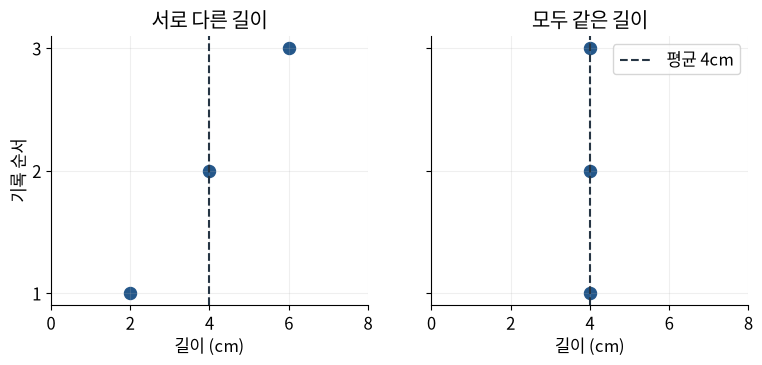

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharex=True, sharey=True)
groups = [("서로 다른 길이", [2, 4, 6]), ("모두 같은 길이", [4, 4, 4])]
for ax, (name, group) in zip(axes, groups):
    ax.scatter(group, [1, 2, 3], s=75, color="#24578A")
    ax.axvline(np.mean(group), color="#263544", linestyle="--", label="평균 4cm")
    ax.set(title=name, xlabel="길이 (cm)", xlim=(0, 8), yticks=[1, 2, 3])
    ax.grid(alpha=0.2)
axes[0].set_ylabel("기록 순서")
axes[1].legend()
plt.show()


#### 장소별 비교는 집계한 양을 먼저 정합니다

장소별 평균 높이는 같은 장소 기록의 높이를 더한 뒤 그 장소의 기록 수로 나눈 값입니다. 실내 평균과 창가 평균을 그린 막대 하나가 화분 하나를 뜻하지는 않습니다.

아래는 **Matplotlib**으로 그린 장소별 평균입니다. 막대는 0에서 시작합니다. 장소마다 기록 수가 3개라는 것도 표에 남깁니다. 한 장소의 높이를 바꾼 복사본으로 다시 계산해 평균과 막대가 어떻게 달라지는지 설명하세요.


,평균 높이(cm),기록 수
place,,
실내,9.333333,3
창가,14.666667,3


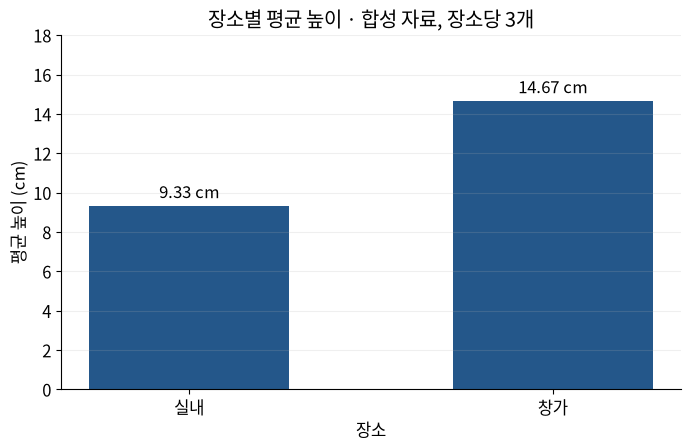

In [20]:
place_summary = plants.groupby("place", sort=True)["height_cm"].agg(["mean", "count"])
display(place_summary.rename(columns={"mean": "평균 높이(cm)", "count": "기록 수"}))
fig, ax = plt.subplots()
bars = ax.bar(place_summary.index, place_summary["mean"],
              color="#24578A", width=0.55)
ax.bar_label(bars, fmt="%.2f cm", padding=4)
ax.set(title="장소별 평균 높이 · 합성 자료, 장소당 3개",
       xlabel="장소", ylabel="평균 높이 (cm)", ylim=(0, 18))
ax.grid(axis="y", alpha=0.2)
plt.show()


#### Seaborn으로도 분포와 범주를 각각 그리기

다음 두 셀은 **Seaborn**을 직접 사용합니다. 첫 그림은 전체 높이의 분포이고, 둘째 그림은 장소별 개별 기록입니다. 분포·범주 비교를 두 라이브러리에서 각각 해 보는 과제이며, 같은 그림을 저장만 하는 것으로 대신하지 않습니다.

히스토그램의 가로축은 높이 구간, 세로축은 그 구간에 들어간 기록 수입니다. 범위는 [6, 10), [10, 14), [14, 18), [18, 22]cm로 읽습니다. 마지막 구간은 오른쪽 끝도 포함합니다. 총 기록 수 6개와 막대의 개수 합을 대조하세요.


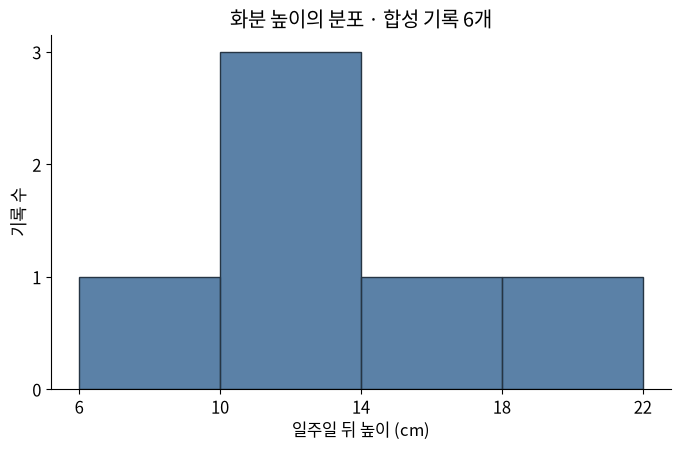

In [21]:
import seaborn as sns

fig, ax = plt.subplots()
sns.histplot(data=plants, x="height_cm", bins=[6, 10, 14, 18, 22],
             color="#24578A", edgecolor="#263544", ax=ax)
ax.set(title="화분 높이의 분포 · 합성 기록 6개",
       xlabel="일주일 뒤 높이 (cm)", ylabel="기록 수",
       xticks=[6, 10, 14, 18, 22], yticks=[0, 1, 2, 3])
plt.show()


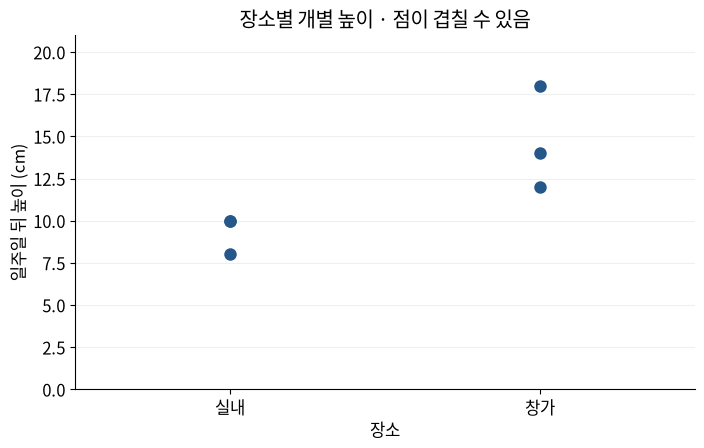

In [22]:
fig, ax = plt.subplots()
sns.stripplot(data=plants, x="place", y="height_cm", order=["실내", "창가"],
              jitter=False, color="#24578A", size=9, ax=ax)
ax.set(title="장소별 개별 높이 · 점이 겹칠 수 있음",
       xlabel="장소", ylabel="일주일 뒤 높이 (cm)", ylim=(0, 21))
ax.grid(axis="y", alpha=0.2)
plt.show()


실내의 10cm 기록 두 개는 같은 위치에 겹칩니다. 그림에서 보이는 점 개수만 세면 기록 수를 적게 셀 수 있습니다. 원자료와 장소별 개수 표를 함께 봅니다. 새 자료에서는 점에 식별자를 붙이거나 겹침을 드러내는 배치를 직접 선택해 보세요.

그림 네 개를 비교하며 ‘막대 하나 또는 점 하나는 무엇인가?’, ‘어떤 값이 집계됐는가?’, ‘같은 평균에 다른 분포가 숨어 있는가?’에 답합니다.


**두 라이브러리 시각화에 내 말로 답하기**

예상한 값 또는 설명:  

계산하거나 판단한 이유:  

실행 뒤 달라진 생각:  

받은 도움: 없음 / 힌트 / 예시 / 직접 설명 중 적기.


### 과제 C · 새 CSV를 읽고, 집계하고, 병합하기

앞의 새 화분 표는 수업 표와 열 이름이 다릅니다. 같은 뜻·단위임을 확인한 뒤 이름을 맞추고, 자료사전을 새로 씁니다. 장소별 평균 높이와 **값이 있는 높이 개수**를 집계하세요.

다음 장소 정보 표를 <code>site</code>로 병합합니다. 이 표에서는 장소가 한 번씩만 나오므로 <code>validate="many_to_one"</code>으로 그 조건을 확인합니다. 병합 뒤 관찰 행 수가 늘지 않았는지, 설명을 못 찾은 장소가 없는지 점검합니다. 아래 셀은 입력만 제공합니다. 집계와 병합 코드는 직접 작성합니다.

~~~python
summary = new_plants.groupby("site")["final_height_cm"].agg(["mean", "count"])
joined = new_plants.merge(site_notes, on="site", how="left",
                          validate="many_to_one")
~~~

다른 장소 이름으로 바꾼 입력에서도 결과를 설명해 보세요. 빈 물 값은 그대로 두며, 높이 평균에 사용한 행 수를 적습니다.


In [23]:
site_notes = pd.DataFrame({"site": ["실내", "창가"],
                           "note": ["실내 관찰 구역", "창가 관찰 구역"]})
display(site_notes)
# 새 셀을 추가해 집계·병합하고 shape, dtypes, 결측 개수를 확인하세요.


,site,note
0,실내,실내 관찰 구역
1,창가,창가 관찰 구역


**새 CSV와 병합에 내 말로 답하기**

예상한 값 또는 설명:  

계산하거나 판단한 이유:  

실행 뒤 달라진 생각:  

받은 도움: 없음 / 힌트 / 예시 / 직접 설명 중 적기.


### 과제 D · 벡터와 내적, 다시 실행하기

**벡터**를 값의 순서가 정해진 목록으로 생각해 봅니다. 두 종류의 화분을 2개, 3개 샀고 한 개 가격이 각각 1000원, 500원이라면 총액은 $2\times1000+3\times500=3500$원입니다.

$$
u\cdot w=\sum_{k=1}^{d}u_k w_k.
$$

$u$는 수량 벡터, $w$는 단가 벡터, $d$는 종류 수이며 여기서는 2입니다. $k$는 같은 종류끼리 짝지을 번호입니다. 수량의 단위는 개, 단가는 원/개이므로 곱의 단위는 원이고, 이를 더한 내적도 원입니다. 두 벡터의 길이가 같고 순서가 같은 종류를 가리킨다고 가정합니다.

1차원 NumPy 배열에서 <code>u * w</code>는 짝별 곱을 남기고, <code>u @ w</code>는 그 곱을 모두 더한 숫자 하나를 냅니다. 단가 순서를 뒤집으면 다른 계산이 되므로 이름과 순서를 같이 확인합니다. 일반적인 벡터의 내적은 방향·길이와도 연결되지만 이번 과제에서는 짝별 곱의 합을 먼저 익힙니다.


In [24]:
quantities = np.array([2, 3])
unit_prices = np.array([1000, 500])
print("종류별 금액(원):", quantities * unit_prices)
print("내적, 총액(원):", quantities @ unit_prices)


종류별 금액(원): [2000 1500]
내적, 총액(원): 3500


수량 [1, 4, 2], 단가 [800, 500, 1200]으로 바꿔 손계산과 코드를 대조합니다. 마지막에는 커널을 재시작하고 노트북 전체를 위에서 아래로 실행합니다. 순서대로 실행했을 때만 필요한 변수를 얻도록 코드를 정리합니다.

제출할 때는 작성한 답안, 자료사전, 두 라이브러리 그림, 바꾼 입력, 실제 시간, 도움을 받은 부분을 함께 남깁니다. 예제와 같은 결과만 저장했다면 새 입력 과제를 아직 수행하지 않은 것입니다.


**내적과 전체 재실행에 내 말로 답하기**

예상한 값 또는 설명:  

계산하거나 판단한 이유:  

실행 뒤 달라진 생각:  

받은 도움: 없음 / 힌트 / 예시 / 직접 설명 중 적기.


## 참고 · 이 교안의 범위와 원자료

이 교안은 승인된 10주 계획 중 **1주차 기본 교안**입니다. 이론 20분, 비코딩 20분(필기 10분 포함), 코딩 80분과 필수 자습 5~7시간을 유지했습니다. 공식 목록의 Python(01), NumPy·pandas(02), Matplotlib·Seaborn(03), 텐서 조작(06)의 배열 선수학습을 연결합니다. 공식 목록에서 이 항목들의 별도 이론 요구 표시는 X이지만, 실제 사용에 필요한 개념과 계산 설명은 포함했습니다. PyTorch의 dtype·device와 GPU 실습은 이 자료에서 완료했다고 주장하지 않으며 6주차 연결로 남깁니다.

[KOAI 2027 공지](https://kitpa.org/koai/2027)가 연결한 [공식 실라버스](https://kitpa.org/koai/syllabus)는 확인 시점에 ‘IOAI 2026 기준’으로 표시돼 있습니다. 공지의 대회 연도와 실라버스의 표기 연도를 구분합니다. 이 교안이나 실행 기록은 공식 시험 문제나 합격 기준이 아닙니다.


자료의 기준은 다음과 같습니다. 저장소는 작성 시작 시 최신 main인 <code>434fe5ad5d23</code>에 고정했습니다.

- [승인 학생용 10주 계획](https://github.com/jlee-ax/AI-Olympiad/blob/434fe5ad5d2300dba741c755bca8928177a2e098/curriculum/student-plan.html)
- [시간·범위 계약](https://github.com/jlee-ax/AI-Olympiad/blob/434fe5ad5d2300dba741c755bca8928177a2e098/curriculum/contract.json)
- [1·2주차 학습 단위 명세](https://github.com/jlee-ax/AI-Olympiad/blob/434fe5ad5d2300dba741c755bca8928177a2e098/skills/koai-evaluate/references/unit-specifications.json)
- [NumPy 평균의 axis·keepdims](https://numpy.org/doc/stable/reference/generated/numpy.mean.html), [분산의 ddof](https://numpy.org/doc/stable/reference/generated/numpy.var.html)
- [pandas CSV 읽기](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html), [결측 확인](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isna.html), [분산 기본값](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.var.html)
- [Seaborn 분포 그림](https://seaborn.pydata.org/generated/seaborn.histplot.html), [개별 점 그림](https://seaborn.pydata.org/generated/seaborn.stripplot.html)

한국어 문장은 [Humanizer-KO 지침](https://github.com/IsaacEryn/humanizer-ko/blob/main/SKILL.md)을 참고해 상투적 예고·과장·번역투를 줄이고 사실과 단위를 보존했습니다. AI가 쓴 글인지 판정하는 도구로 사용하지 않았습니다. 수업 자료를 이해하는 데 필요한 정의·가정·풀이 단계는 생략하지 않았습니다.
